DS6-SCTP-DSAI-Module3-MoneyBall Analytics

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are now expected on the local filesystem. Set LOCAL_DATA_DIR
# (or rely on the notebook's working directory) to point to the folder that
# contains data.csv, predict.csv, etc.

import os
from pathlib import Path

LOCAL_DATA_DIR = Path("/home/sipei/Moneyball").resolve()
print(f"LOCAL_DATA_DIR set to {LOCAL_DATA_DIR}")

LOCAL_DATA_DIR set to /home/sipei/Moneyball


In [2]:
## Starter Code for Building Baseball Win Prediction Model

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Load the pre-processed datasets from the directory pointed to by LOCAL_DATA_DIR
DATA_DIR = LOCAL_DATA_DIR  # defined in the previous cell
print(f"Loading datasets from {DATA_DIR}")

data_df = pd.read_csv(DATA_DIR / "data.csv")
predict_df = pd.read_csv(DATA_DIR / "predict.csv")

# Display basic information about the datasets
print(f"Data set shape: {data_df.shape}")
print(f"Predict set shape: {predict_df.shape}")

Loading datasets from /home/sipei/Moneyball
Data set shape: (1412, 51)
Predict set shape: (400, 47)


In [3]:
# Use every numeric/boolean column shared by data.csv and predict.csv
# (drops the target, identifiers and text labels automatically)
exclude_cols = {'W', 'ID', 'yearID', 'teamID', 'year_label', 'decade_label', 'win_bins'}

shared_cols = [col for col in data_df.columns if col in predict_df.columns]
available_features = [
    col for col in data_df[shared_cols].select_dtypes(include=['number', 'bool']).columns
    if col not in exclude_cols
]
print(f"Number of available features: {len(available_features)}")

Number of available features: 44


In [4]:
# Separate features and target variable
X = data_df[available_features]
y = data_df['W']

# Perform the split (adjust test_size / random_state as needed)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% for testing
    random_state=42    # ensures reproducibility
)

In [5]:
# Scale features
# Identify columns to exclude from scaling (one-hot encoded and label columns)
one_hot_cols = [col for col in X_train.columns if col.startswith(('era_', 'decade_'))]
other_cols = [col for col in X_train.columns if col not in one_hot_cols]

# Scale only non-one-hot features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[other_cols] = scaler.fit_transform(X_train[other_cols])
X_test_scaled[other_cols] = scaler.transform(X_test[other_cols])

In [6]:
# Build Linear Regression Model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_train_preds = lr.predict(X_train_scaled)
lr_test_preds = lr.predict(X_test_scaled)

# Evaluate Linear Regression
lr_train_mae = mean_absolute_error(y_train, lr_train_preds)
lr_test_mae = mean_absolute_error(y_test, lr_test_preds)
lr_test_rmse = np.sqrt(mean_squared_error(y_test, lr_test_preds))
lr_test_r2 = r2_score(y_test, lr_test_preds)

print(f"Linear Regression Performance:")
print(f"  Training MAE: {lr_train_mae:.4f}")
print(f"  Test MAE: {lr_test_mae:.4f}")
print(f"  Test RMSE: {lr_test_rmse:.4f}")
print(f"  Test R²: {lr_test_r2:.4f}")

# Feature importance from Linear Regression
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))


Linear Regression Performance:
  Training MAE: 2.6749
  Test MAE: 2.7025
  Test RMSE: 3.3310
  Test R²: 0.9306

Top 10 Most Important Features:
   Feature  Coefficient
1        R     8.866279
16  IPouts     6.437929
2       AB    -6.108157
10      RA    -5.629822
11      ER    -4.724867
15      SV     4.107003
12     ERA     3.973551
13      CG     3.407080
3        H     3.133752
21       E    -3.062916


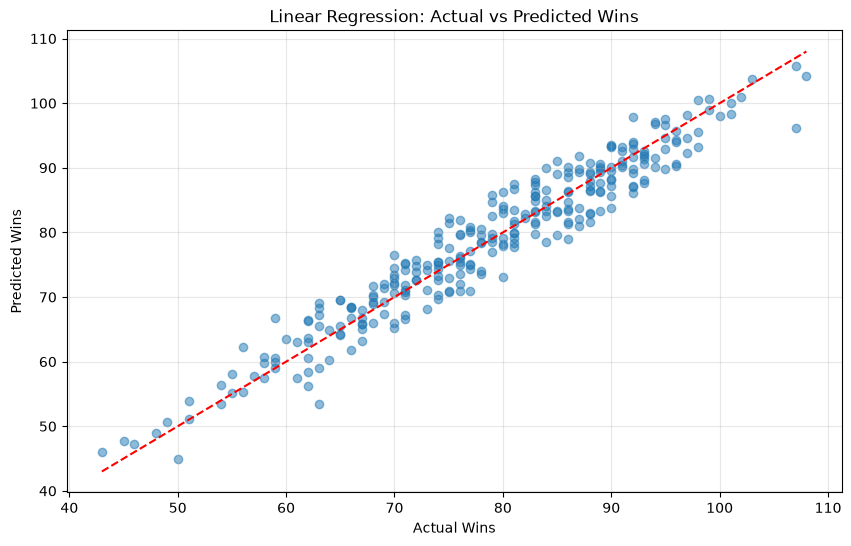

In [7]:
#Visualize actu#al vs predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, lr_test_preds, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Wins')
plt.ylabel('Predicted Wins')
plt.title('Linear Regression: Actual vs Predicted Wins')
plt.grid(True, alpha=0.3)

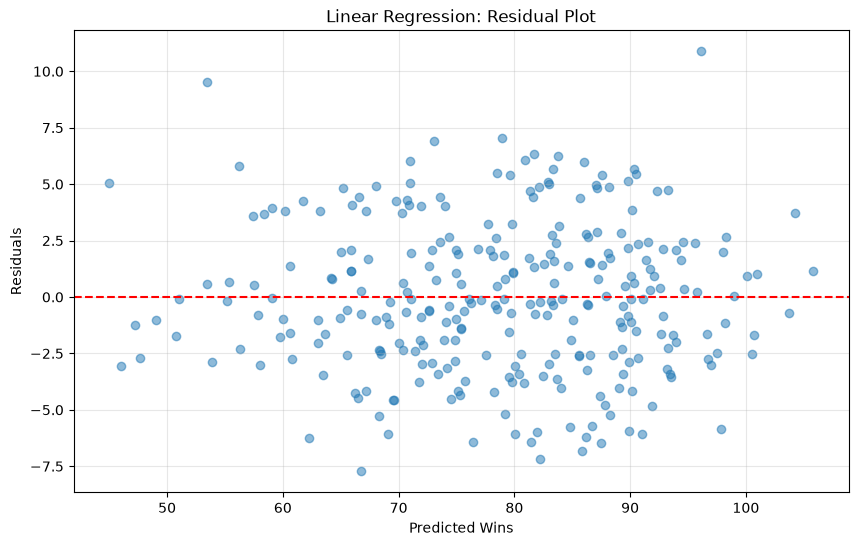

In [8]:
# Add residual plot
plt.figure(figsize=(10, 6))
residuals = y_test - lr_test_preds
plt.scatter(lr_test_preds, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Wins')
plt.ylabel('Residuals')
plt.title('Linear Regression: Residual Plot')
plt.grid(True, alpha=0.3)
plt.show()


In [10]:
#Build ElasticNetCV
from sklearn.linear_model import ElasticNetCV

# Train ElasticNet with cross-validation
elastic = ElasticNetCV(cv=5, random_state=42)
elastic.fit(X_train_scaled, y_train)

elastic_train_preds = elastic.predict(X_train_scaled)
elastic_test_preds = elastic.predict(X_test_scaled)

# Evaluate ElasticNet
elastic_train_mae = mean_absolute_error(y_train, elastic_train_preds)
elastic_test_mae = mean_absolute_error(y_test, elastic_test_preds)
elastic_test_rmse = np.sqrt(mean_squared_error(y_test, elastic_test_preds))
elastic_test_r2 = r2_score(y_test, elastic_test_preds)

print(f"\nElasticNet Performance:")
print(f"  Best alpha: {elastic.alpha_}")
print(f"  Best l1_ratio: {elastic.l1_ratio_}")
print(f"  Training MAE: {elastic_train_mae:.4f}")
print(f"  Test MAE: {elastic_test_mae:.4f}")
print(f"  Test RMSE: {elastic_test_rmse:.4f}")
print(f"  Test R²: {elastic_test_r2:.4f}")


ElasticNet Performance:
  Best alpha: 0.015840216303331628
  Best l1_ratio: 0.5
  Training MAE: 2.7311
  Test MAE: 2.7390
  Test RMSE: 3.3857
  Test R²: 0.9283



Top 10 Most Important Features (ElasticNet):
        Feature  Coefficient
1             R     8.154065
10           RA    -4.764063
16       IPouts     3.915326
15           SV     3.883399
2            AB    -3.833323
13           CG     2.979085
3             H     2.351946
36  decade_1940     1.382722
12          ERA    -1.271540
21            E    -1.168636


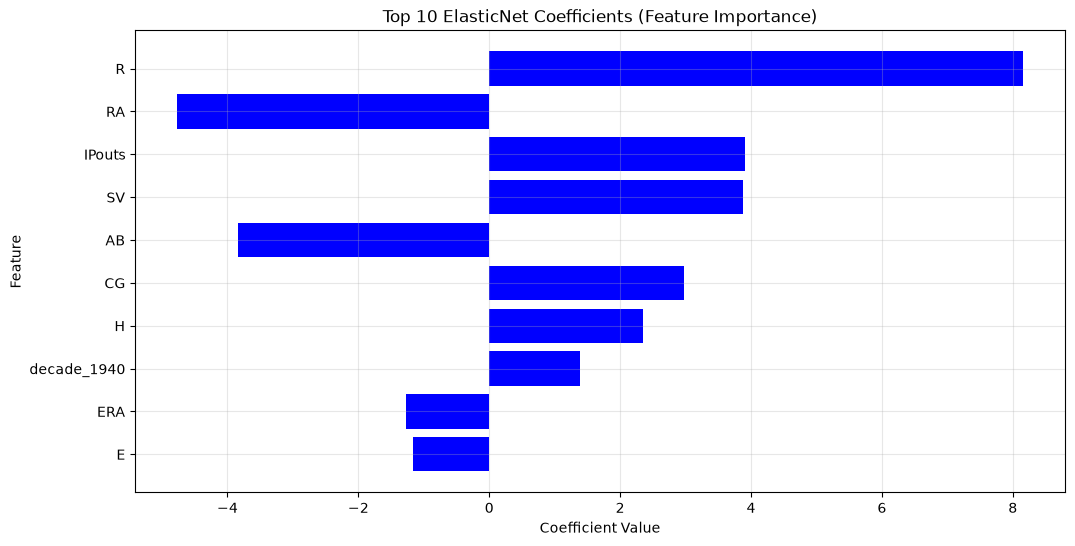

In [11]:
#Feature Importance from ElasticNet
elastic_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': elastic.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("\nTop 10 Most Important Features (ElasticNet):")
print(elastic_importance.head(10))

# Bar chart of ElasticNet coefficients
plt.figure(figsize=(12, 6))
coef_sorted = elastic_importance.sort_values("Coefficient", key=abs, ascending=False)

plt.barh(coef_sorted["Feature"][:10], coef_sorted["Coefficient"][:10], color="blue")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 10 ElasticNet Coefficients (Feature Importance)")
plt.gca().invert_yaxis()  # largest at the top
plt.grid(True, alpha=0.3)
plt.show()


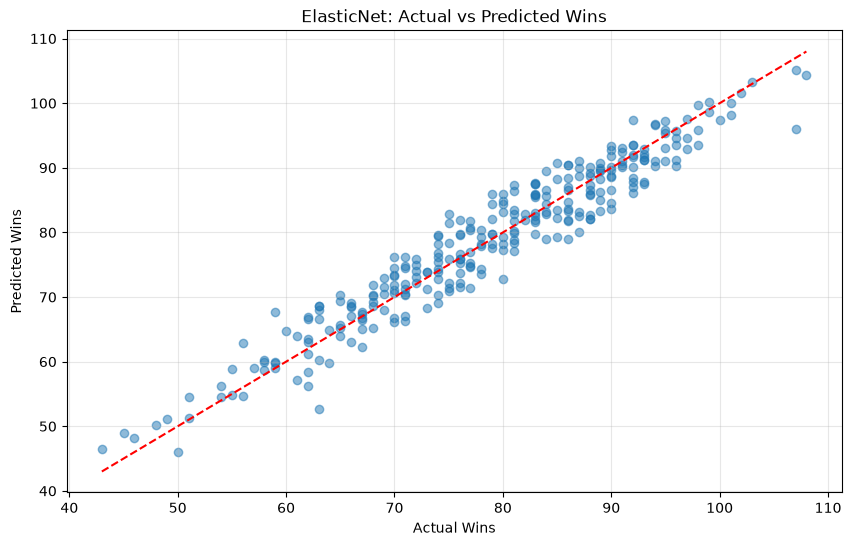

In [12]:
 #Visualize actu#al vs predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, elastic_test_preds, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Wins')
plt.ylabel('Predicted Wins')
plt.title('ElasticNet: Actual vs Predicted Wins')
plt.grid(True, alpha=0.3)
plt.show()


In [14]:
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# --- 1. ElasticNet (single train/test split) ---
elastic_no_cv = ElasticNet(random_state=42)
elastic_no_cv.fit(X_train_scaled, y_train)

preds_no_cv = elastic_no_cv.predict(X_test_scaled)
no_cv_mae = mean_absolute_error(y_test, preds_no_cv)
no_cv_rmse = np.sqrt(mean_squared_error(y_test, preds_no_cv))
no_cv_r2 = r2_score(y_test, preds_no_cv)

print("\nElasticNet (No CV, single split):")
print(f"  Test MAE: {no_cv_mae:.4f}")
print(f"  Test RMSE: {no_cv_rmse:.4f}")
print(f"  Test R²: {no_cv_r2:.4f}")

# --- 2. ElasticNet with 5-fold CV ---
elastic_cv = ElasticNet(random_state=42)

cv_results = cross_validate(
    elastic_cv,
    X_train_scaled,
    y_train,
    cv=5,
    scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"]
)

cv_mae = -cv_results["test_neg_mean_absolute_error"].mean()
cv_rmse = -cv_results["test_neg_root_mean_squared_error"].mean()
cv_r2 = cv_results["test_r2"].mean()

print("\nElasticNet (5-Fold CV):")
print(f"  Mean MAE: {cv_mae:.4f}")
print(f"  Mean RMSE: {cv_rmse:.4f}")
print(f"  Mean R²: {cv_r2:.4f}")




ElasticNet (No CV, single split):
  Test MAE: 4.2385
  Test RMSE: 5.1374
  Test R²: 0.8348

ElasticNet (5-Fold CV):
  Mean MAE: 4.2622
  Mean RMSE: 5.3121
  Mean R²: 0.8433


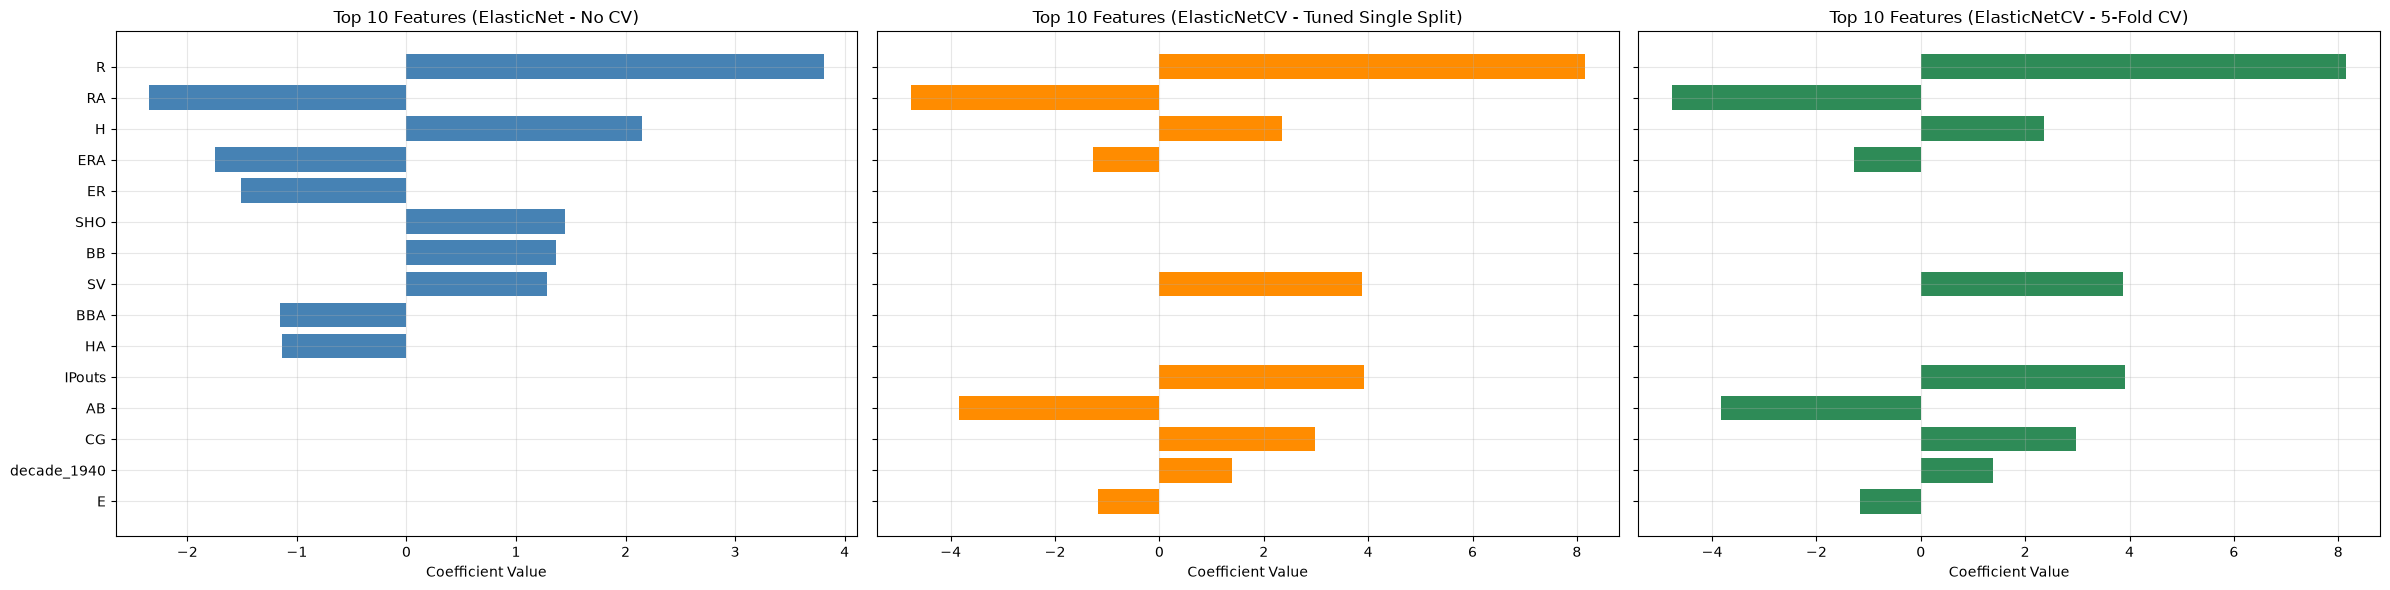


Performance Comparison:
                      Model      MAE     RMSE       R²
         ElasticNet (No CV) 4.238532 5.137437 0.834831
ElasticNetCV (Single Split) 2.738956 3.385749 0.928263
   ElasticNetCV (5-Fold CV) 2.825211 3.558603 0.929599

Top 10 Feature Coefficients Comparison:
                  No CV ElasticNetCV Single Split ElasticNetCV 5-Fold CV
            Coefficient               Coefficient            Coefficient
Feature                                                                 
R              3.807044                  8.154065               8.154065
RA            -2.345801                 -4.764063              -4.764063
H              2.153654                  2.351946               2.351946
ERA           -1.749176                 -1.271540              -1.271540
ER            -1.509587                       NaN                    NaN
SHO            1.446928                       NaN                    NaN
BB             1.362036                       NaN        

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import ElasticNet, ElasticNetCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate

# --- 1. ElasticNet (No CV, defaults) ---
elastic_no_cv = ElasticNet(random_state=42)
elastic_no_cv.fit(X_train_scaled, y_train)
preds_no_cv = elastic_no_cv.predict(X_test_scaled)

importance_no_cv = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": elastic_no_cv.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

no_cv_mae = mean_absolute_error(y_test, preds_no_cv)
no_cv_rmse = np.sqrt(mean_squared_error(y_test, preds_no_cv))
no_cv_r2 = r2_score(y_test, preds_no_cv)

# --- 2. ElasticNetCV (single split, tuned) ---
elastic_cv_single = ElasticNetCV(cv=5, random_state=42)
elastic_cv_single.fit(X_train_scaled, y_train)
preds_cv_single = elastic_cv_single.predict(X_test_scaled)

importance_cv_single = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": elastic_cv_single.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

cv_single_mae = mean_absolute_error(y_test, preds_cv_single)
cv_single_rmse = np.sqrt(mean_squared_error(y_test, preds_cv_single))
cv_single_r2 = r2_score(y_test, preds_cv_single)

# --- 3. ElasticNetCV (5-fold CV evaluation) ---
elastic_cv_five = ElasticNetCV(cv=5, random_state=42)
elastic_cv_five.fit(X_train_scaled, y_train)

importance_cv_five = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": elastic_cv_five.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

cv_results = cross_validate(
    elastic_cv_five,
    X_train_scaled,
    y_train,
    cv=5,
    scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"]
)
cv_five_mae = -cv_results["test_neg_mean_absolute_error"].mean()
cv_five_rmse = -cv_results["test_neg_root_mean_squared_error"].mean()
cv_five_r2 = cv_results["test_r2"].mean()

# --- Plot 3 charts side-by-side ---
fig, axes = plt.subplots(1, 3, figsize=(24, 6), sharey=True)

axes[0].barh(importance_no_cv["Feature"], importance_no_cv["Coefficient"], color="steelblue")
axes[0].set_title("Top 10 Features (ElasticNet - No CV)")
axes[0].set_xlabel("Coefficient Value")
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3)

axes[1].barh(importance_cv_single["Feature"], importance_cv_single["Coefficient"], color="darkorange")
axes[1].set_title("Top 10 Features (ElasticNetCV - Tuned Single Split)")
axes[1].set_xlabel("Coefficient Value")
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3)

axes[2].barh(importance_cv_five["Feature"], importance_cv_five["Coefficient"], color="seagreen")
axes[2].set_title("Top 10 Features (ElasticNetCV - 5-Fold CV)")
axes[2].set_xlabel("Coefficient Value")
axes[2].invert_yaxis()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Performance comparison table ---
results = pd.DataFrame([
    {"Model": "ElasticNet (No CV)", "MAE": no_cv_mae, "RMSE": no_cv_rmse, "R²": no_cv_r2},
    {"Model": "ElasticNetCV (Single Split)", "MAE": cv_single_mae, "RMSE": cv_single_rmse, "R²": cv_single_r2},
    {"Model": "ElasticNetCV (5-Fold CV)", "MAE": cv_five_mae, "RMSE": cv_five_rmse, "R²": cv_five_r2}
])

print("\nPerformance Comparison:")
print(results.to_string(index=False))
# Combine top 10 features from each setup
top_features_no_cv = importance_no_cv.head(10).set_index("Feature")
top_features_cv_single = importance_cv_single.head(10).set_index("Feature")
top_features_cv_five = importance_cv_five.head(10).set_index("Feature")

# Merge into one table
comparison_table = pd.concat(
    [top_features_no_cv, top_features_cv_single, top_features_cv_five],
    axis=1,
    keys=["No CV", "ElasticNetCV Single Split", "ElasticNetCV 5-Fold CV"]
)

print("\nTop 10 Feature Coefficients Comparison:")
print(comparison_table.to_string())

In [22]:
# --- Feature Engineering  ---

# 1. Run Differential
data_df["RunDiff"] = data_df["R"] - data_df["RA"]
predict_df["RunDiff"] = predict_df["R"] - predict_df["RA"]

# 2. Per-Game Rates
data_df["R_perG"] = data_df["R"] / data_df["G"]
data_df["H_perG"] = data_df["H"] / data_df["G"]
predict_df["R_perG"] = predict_df["R"] / predict_df["G"]
predict_df["H_perG"] = predict_df["H"] / predict_df["G"]

# 3. Efficiency Ratios
data_df["BattingAvg"] = data_df["H"] / data_df["AB"]
data_df["SO_perOut"] = data_df["SO"] / data_df["IPouts"]
predict_df["BattingAvg"] = predict_df["H"] / predict_df["AB"]
predict_df["SO_perOut"] = predict_df["SO"] / predict_df["IPouts"]

# 4. Composite Pitching Strength
data_df["PitchStrength"] = data_df["IPouts"] / data_df["ERA"]
predict_df["PitchStrength"] = predict_df["IPouts"] / predict_df["ERA"]

# 5. Era Adjustment (only for training data, since predict_df has no yearID)
if "yearID" in data_df.columns:
    data_df["R_adj"] = data_df["R"] / data_df.groupby("yearID")["R"].transform("mean")
else:
    print("Skipping era adjustment: 'yearID' not found in data_df")


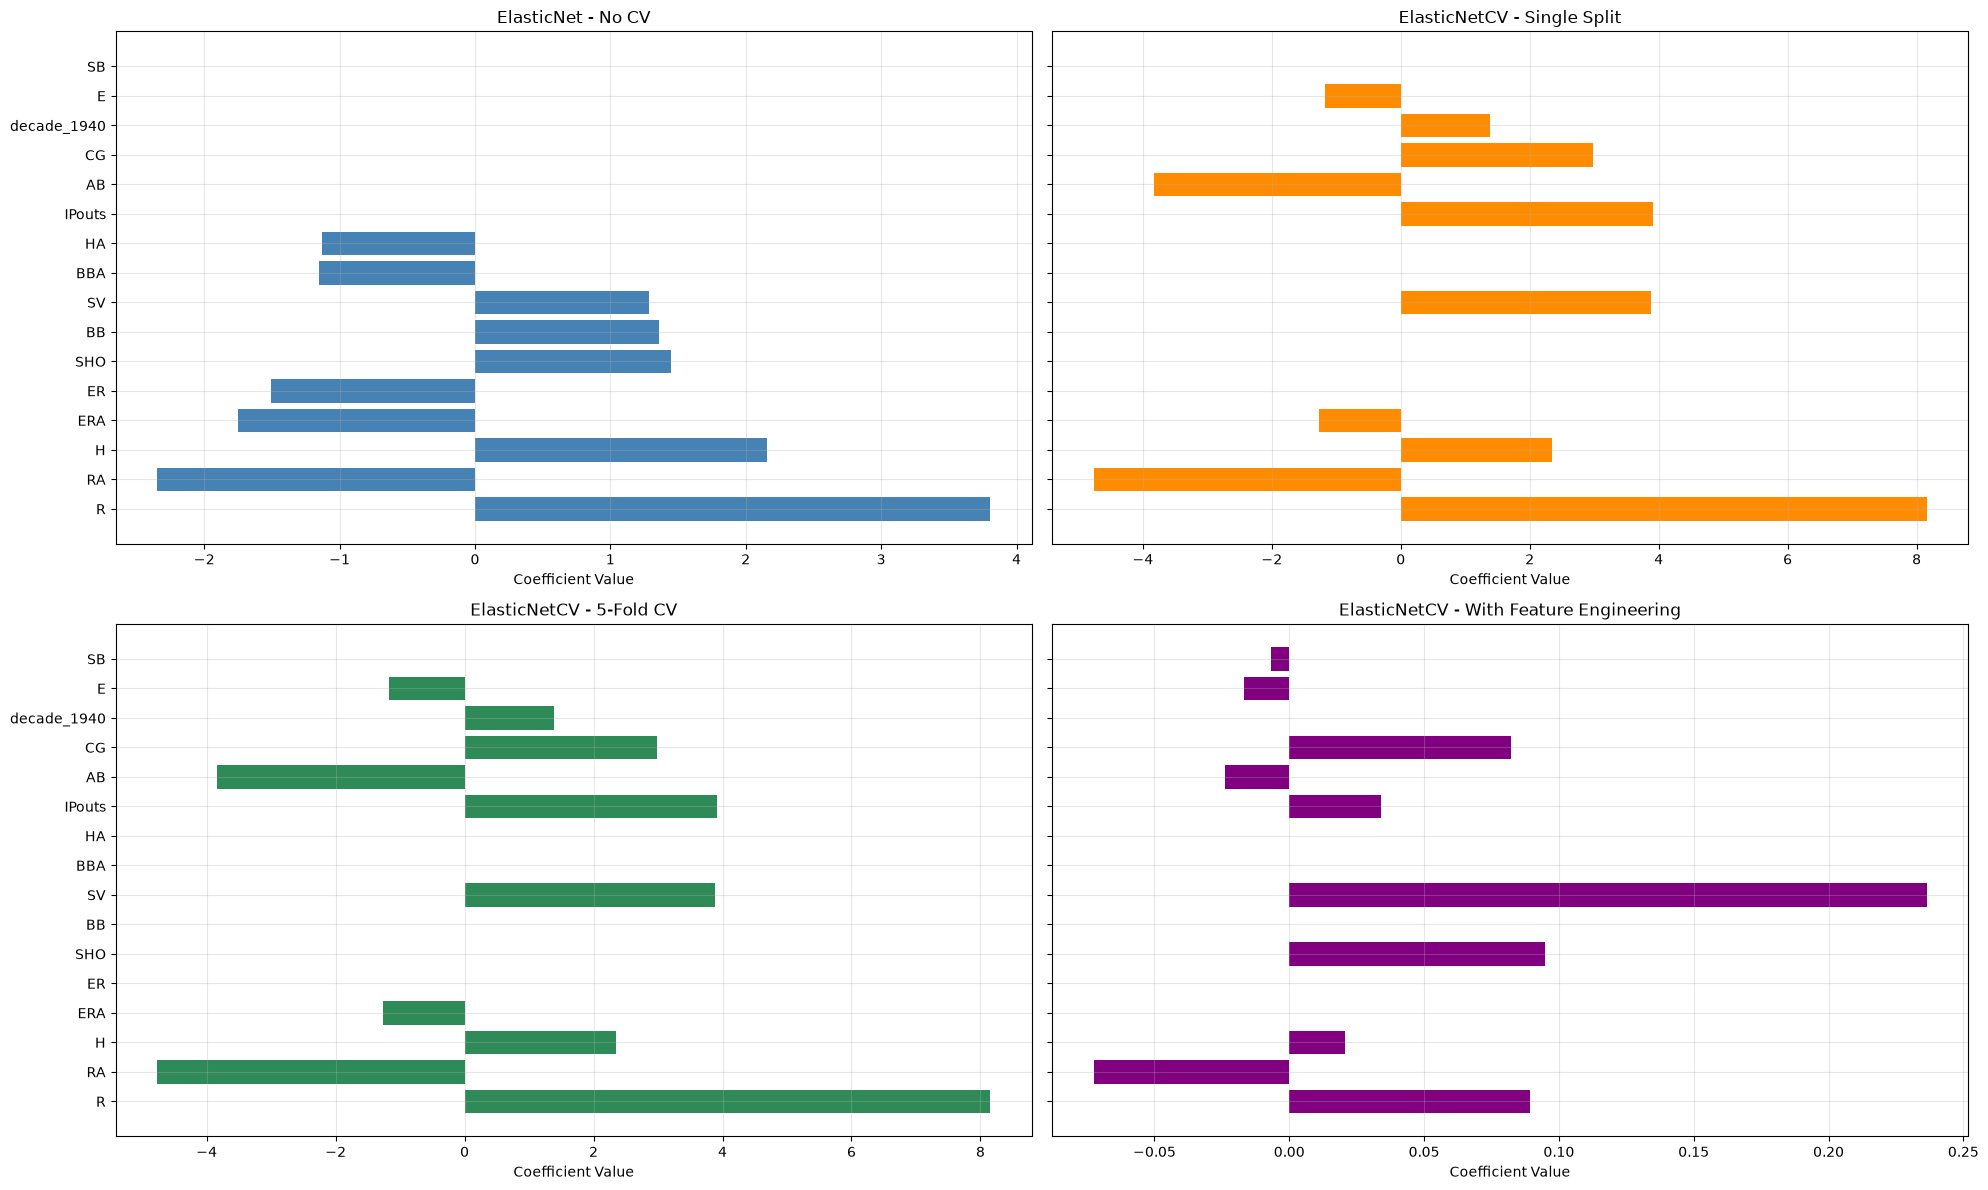


Performance Comparison:
                      Model      MAE     RMSE       R²
         ElasticNet (No CV) 4.238532 5.137437 0.834831
ElasticNetCV (Single Split) 2.738956 3.385749 0.928263
   ElasticNetCV (5-Fold CV) 2.825211 3.558603 0.929599
 ElasticNetCV (Feature Eng) 2.780565 3.494823 0.930852

Top 10 Feature Coefficients Comparison:
            ElasticNet No CV ElasticNetCV Single Split ElasticNetCV 5-Fold CV ElasticNetCV Feature Eng
                 Coefficient               Coefficient            Coefficient              Coefficient
Feature                                                                                               
R                   3.807044                  8.154065               8.154065                 0.089348
RA                 -2.345801                 -4.764063              -4.764063                -0.072583
H                   2.153654                  2.351946               2.351946                 0.020841
ERA                -1.749176             

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import ElasticNet, ElasticNetCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate

# --- 1. ElasticNet (No CV) ---
elastic_no_cv = ElasticNet(random_state=42)
elastic_no_cv.fit(X_train_scaled, y_train)
preds_no_cv = elastic_no_cv.predict(X_test_scaled)

importance_no_cv = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": elastic_no_cv.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

no_cv_mae = mean_absolute_error(y_test, preds_no_cv)
no_cv_rmse = np.sqrt(mean_squared_error(y_test, preds_no_cv))
no_cv_r2 = r2_score(y_test, preds_no_cv)

# --- 2. ElasticNetCV (Single Split Tuned) ---
elastic_cv_single = ElasticNetCV(cv=5, random_state=42)
elastic_cv_single.fit(X_train_scaled, y_train)
preds_cv_single = elastic_cv_single.predict(X_test_scaled)

importance_cv_single = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": elastic_cv_single.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

cv_single_mae = mean_absolute_error(y_test, preds_cv_single)
cv_single_rmse = np.sqrt(mean_squared_error(y_test, preds_cv_single))
cv_single_r2 = r2_score(y_test, preds_cv_single)

# --- 3. ElasticNetCV (5-Fold CV Evaluation) ---
elastic_cv_five = ElasticNetCV(cv=5, random_state=42)
elastic_cv_five.fit(X_train_scaled, y_train)

importance_cv_five = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": elastic_cv_five.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

cv_results = cross_validate(
    elastic_cv_five,
    X_train_scaled,
    y_train,
    cv=5,
    scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"]
)
cv_five_mae = -cv_results["test_neg_mean_absolute_error"].mean()
cv_five_rmse = -cv_results["test_neg_root_mean_squared_error"].mean()
cv_five_r2 = cv_results["test_r2"].mean()

# --- 4. ElasticNetCV (With Feature Engineering) ---
elastic_cv_feat = ElasticNetCV(cv=5, random_state=42)
elastic_cv_feat.fit(data_df[available_features], data_df["W"])
preds_cv_feat = elastic_cv_feat.predict(data_df[available_features])

importance_cv_feat = pd.DataFrame({
    "Feature": data_df[available_features].columns,
    "Coefficient": elastic_cv_feat.coef_
}).sort_values("Coefficient", key=abs, ascending=False).head(10)

cv_feat_mae = mean_absolute_error(data_df["W"], preds_cv_feat)
cv_feat_rmse = np.sqrt(mean_squared_error(data_df["W"], preds_cv_feat))
cv_feat_r2 = r2_score(data_df["W"], preds_cv_feat)

# --- Plot 2x2 charts ---
fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharey=True)

axes[0,0].barh(importance_no_cv["Feature"], importance_no_cv["Coefficient"], color="steelblue")
axes[0,0].set_title("ElasticNet - No CV")
axes[0,0].set_xlabel("Coefficient Value")
axes[0,0].invert_yaxis()
axes[0,0].grid(True, alpha=0.3)

axes[0,1].barh(importance_cv_single["Feature"], importance_cv_single["Coefficient"], color="darkorange")
axes[0,1].set_title("ElasticNetCV - Single Split")
axes[0,1].set_xlabel("Coefficient Value")
axes[0,1].invert_yaxis()
axes[0,1].grid(True, alpha=0.3)

axes[1,0].barh(importance_cv_five["Feature"], importance_cv_five["Coefficient"], color="seagreen")
axes[1,0].set_title("ElasticNetCV - 5-Fold CV")
axes[1,0].set_xlabel("Coefficient Value")
axes[1,0].invert_yaxis()
axes[1,0].grid(True, alpha=0.3)

axes[1,1].barh(importance_cv_feat["Feature"], importance_cv_feat["Coefficient"], color="purple")
axes[1,1].set_title("ElasticNetCV - With Feature Engineering")
axes[1,1].set_xlabel("Coefficient Value")
axes[1,1].invert_yaxis()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Performance comparison table ---
results = pd.DataFrame([
    {"Model": "ElasticNet (No CV)", "MAE": no_cv_mae, "RMSE": no_cv_rmse, "R²": no_cv_r2},
    {"Model": "ElasticNetCV (Single Split)", "MAE": cv_single_mae, "RMSE": cv_single_rmse, "R²": cv_single_r2},
    {"Model": "ElasticNetCV (5-Fold CV)", "MAE": cv_five_mae, "RMSE": cv_five_rmse, "R²": cv_five_r2},
    {"Model": "ElasticNetCV (Feature Eng)", "MAE": cv_feat_mae, "RMSE": cv_feat_rmse, "R²": cv_feat_r2}
])

print("\nPerformance Comparison:")
print(results.to_string(index=False))

# --- Top 10 coefficients table ---
comparison_table = pd.concat(
    [importance_no_cv.set_index("Feature"),
     importance_cv_single.set_index("Feature"),
     importance_cv_five.set_index("Feature"),
     importance_cv_feat.set_index("Feature")],
    axis=1,
    keys=["ElasticNet No CV", "ElasticNetCV Single Split", "ElasticNetCV 5-Fold CV", "ElasticNetCV Feature Eng"]
)

print("\nTop 10 Feature Coefficients Comparison:")
print(comparison_table.to_string())



               Model  Train MAE  Test MAE  Test RMSE   Test R²
0  Linear Regression   2.674883  2.702496   3.330954  0.930566
1         ElasticNet   2.731119  2.738956   3.385749  0.928263
        Feature  Linear Coef  ElasticNet Coef
1             R     8.866279         8.154065
10           RA    -5.629822        -4.764063
16       IPouts     6.437929         3.915326
15           SV     4.107003         3.883399
2            AB    -6.108157        -3.833323
13           CG     3.407080         2.979085
3             H     3.133752         2.351946
36  decade_1940     2.145221         1.382722
12          ERA     3.973551        -1.271540
21            E    -3.062916        -1.168636
11           ER    -4.724867        -0.957639
14          SHO     0.746386         0.902636
19          BBA    -0.815258        -0.804189
33  decade_1910    -1.251302        -0.774105
25        era_1    -1.251302        -0.773797


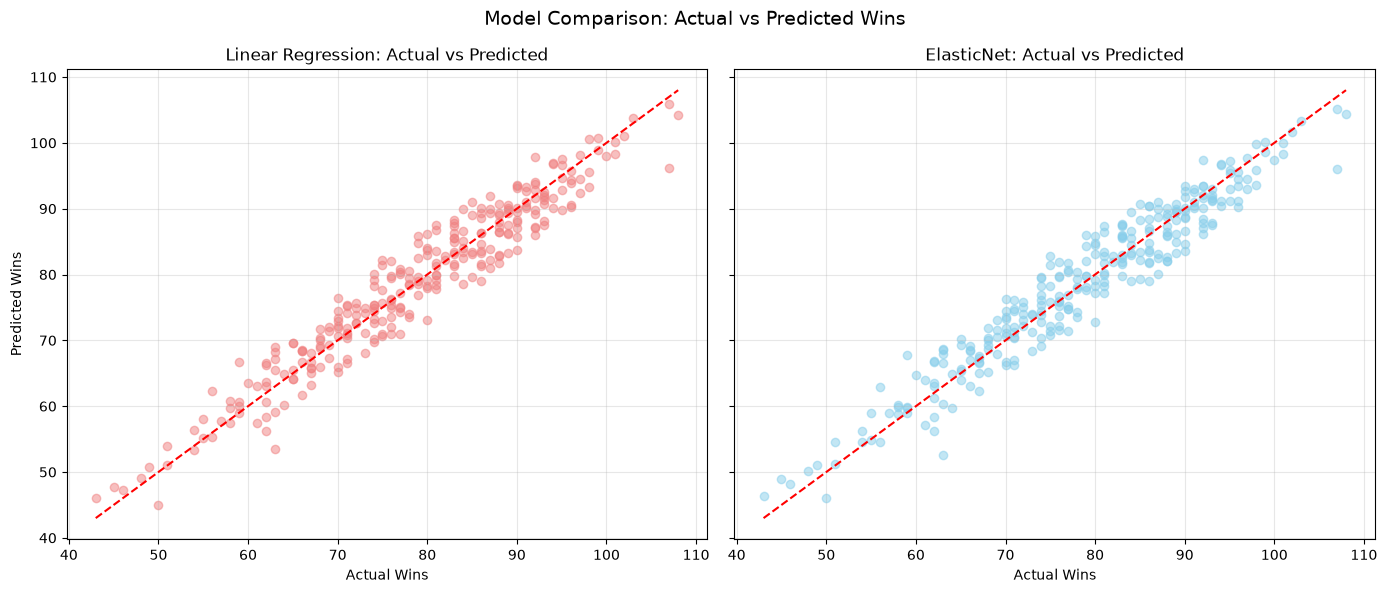

In [68]:
# Collect metrics into a DataFrame for easy comparison
results = pd.DataFrame({
    "Model": ["Linear Regression", "ElasticNet"],
    "Train MAE": [lr_train_mae, elastic_train_mae],
    "Test MAE": [lr_test_mae, elastic_test_mae],
    "Test RMSE": [lr_test_rmse, elastic_test_rmse],
    "Test R²": [lr_test_r2, elastic_test_r2]
})

print(results)

# Merge coefficients side-by-side
coef_compare = pd.DataFrame({
    "Feature": X_train.columns,
    "Linear Coef": lr.coef_,
    "ElasticNet Coef": elastic.coef_
}).sort_values("ElasticNet Coef", key=abs, ascending=False)

print(coef_compare.head(15))  # Top 15 features by ElasticNet weight

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Linear Regression
axes[0].scatter(y_test, lr_test_preds, alpha=0.5, color="lightcoral")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title("Linear Regression: Actual vs Predicted")
axes[0].set_xlabel("Actual Wins")
axes[0].set_ylabel("Predicted Wins")
axes[0].grid(True, alpha=0.3)

# ElasticNet
axes[1].scatter(y_test, elastic_test_preds, alpha=0.5, color="skyblue")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_title("ElasticNet: Actual vs Predicted")
axes[1].set_xlabel("Actual Wins")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Model Comparison: Actual vs Predicted Wins", fontsize=14)
plt.tight_layout()
plt.show()


📊 Performance metrics:
Linear Regression edges out slightly with lower RMSE and higher R².
ElasticNet is very close, but trades a tiny bit of accuracy for stability.

⚖️ Coefficients:
Notice how ElasticNet pulls extreme values (like IPouts, AB, ER, ERA) closer to zero.
This reduces the influence of noisy or highly correlated stats, making the model more robust across different eras.
Features like R and RA remain strong drivers in both models, but ElasticNet dampens them slightly.

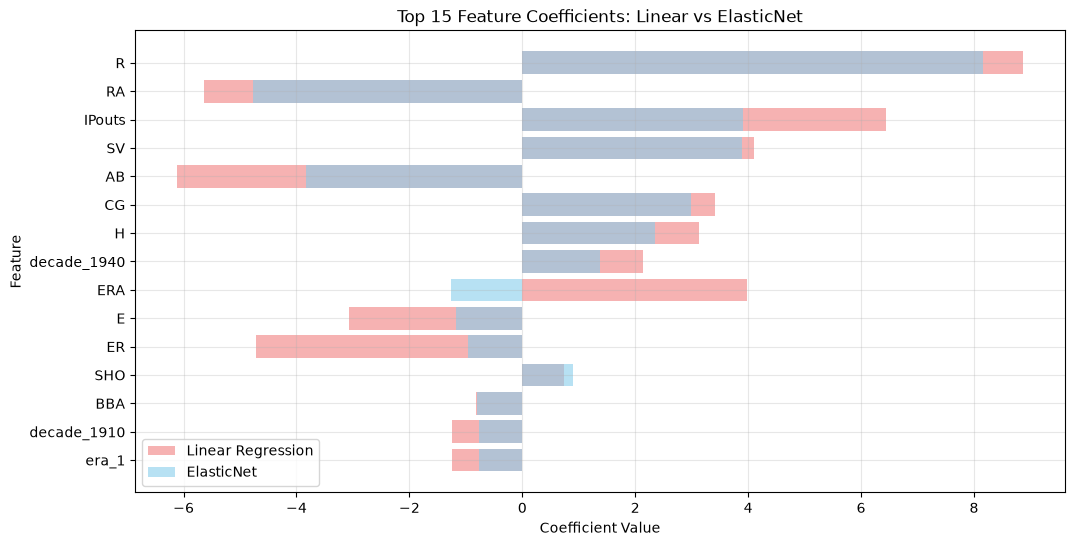

In [69]:
plt.figure(figsize=(12, 6))

# Sort by ElasticNet absolute coefficient
coef_sorted = coef_compare.sort_values("ElasticNet Coef", key=abs, ascending=False).head(15)

plt.barh(coef_sorted["Feature"], coef_sorted["Linear Coef"], 
         color="lightcoral", alpha=0.6, label="Linear Regression")
plt.barh(coef_sorted["Feature"], coef_sorted["ElasticNet Coef"], 
         color="skyblue", alpha=0.6, label="ElasticNet")

plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 15 Feature Coefficients: Linear vs ElasticNet")
plt.legend()
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.show()


Runs scored (R) and Runs allowed (RA) are the most critical predictors — they dominate both models.
Pitching depth (IPouts, Saves) also matters significantly.
ElasticNet trims down redundant stats (ERA, ER, Errors) to avoid overfitting.

In [8]:
from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5)
ridge.fit(X_train_scaled, y_train)
ridge_train_preds = ridge.predict(X_train_scaled)
ridge_test_preds = ridge.predict(X_test_scaled)

print("\nRidge Regression")
print("  Best alpha:", ridge.alpha_)
print("  Train MAE:", mean_absolute_error(y_train, ridge_train_preds))
print("  Test MAE:", mean_absolute_error(y_test, ridge_test_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, ridge_test_preds)))
print("  Test R²:", r2_score(y_test, ridge_test_preds))


Ridge Regression
  Best alpha: 2.023589647725158
  Train MAE: 2.682394179696905
  Test MAE: 2.703757660646513
  Test RMSE: 3.3348692624691805
  Test R²: 0.9304024601469608


In [9]:
from sklearn.linear_model import LassoCV

lasso = LassoCV(alphas=np.logspace(-3, 3, 50), cv=5, max_iter=5000)
lasso.fit(X_train_scaled, y_train)
lasso_train_preds = lasso.predict(X_train_scaled)
lasso_test_preds = lasso.predict(X_test_scaled)

print("\nLasso Regression")
print("  Best alpha:", lasso.alpha_)
print("  Train MAE:", mean_absolute_error(y_train, lasso_train_preds))
print("  Test MAE:", mean_absolute_error(y_test, lasso_test_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, lasso_test_preds)))
print("  Test R²:", r2_score(y_test, lasso_test_preds))


Lasso Regression
  Best alpha: 0.009540954763499945
  Train MAE: 2.694673734622999
  Test MAE: 2.68991339949852
  Test RMSE: 3.324601436925813
  Test R²: 0.9308303721376754


/home/sipei/miniconda3/envs/dsai-m3/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.126209e+01, tolerance: 1.634e+01
  model = cd_fast.enet_coordinate_descent_gram(


In [72]:
# Build comparison DataFrame
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "Lasso", "ElasticNet"],
    "Train MAE": [
        mean_absolute_error(y_train, lr_train_preds),
        mean_absolute_error(y_train, ridge_train_preds),
        mean_absolute_error(y_train, lasso_train_preds),
        mean_absolute_error(y_train, elastic_train_preds)
    ],
    "Test MAE": [
        mean_absolute_error(y_test, lr_test_preds),
        mean_absolute_error(y_test, ridge_test_preds),
        mean_absolute_error(y_test, lasso_test_preds),
        mean_absolute_error(y_test, elastic_test_preds)
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_test_preds)),
        np.sqrt(mean_squared_error(y_test, ridge_test_preds)),
        np.sqrt(mean_squared_error(y_test, lasso_test_preds)),
        np.sqrt(mean_squared_error(y_test, elastic_test_preds))
    ],
    "Test R²": [
        r2_score(y_test, lr_test_preds),
        r2_score(y_test, ridge_test_preds),
        r2_score(y_test, lasso_test_preds),
        r2_score(y_test, elastic_test_preds)
    ]
})

# Display neatly
print("\nModel Performance Comparison:")
print(results.to_string(index=False))



Model Performance Comparison:
            Model  Train MAE  Test MAE  Test RMSE  Test R²
Linear Regression   2.674883  2.702496   3.330954 0.930566
            Ridge   2.682394  2.703758   3.334869 0.930402
            Lasso   2.694674  2.689913   3.324601 0.930830
       ElasticNet   2.731119  2.738956   3.385749 0.928263


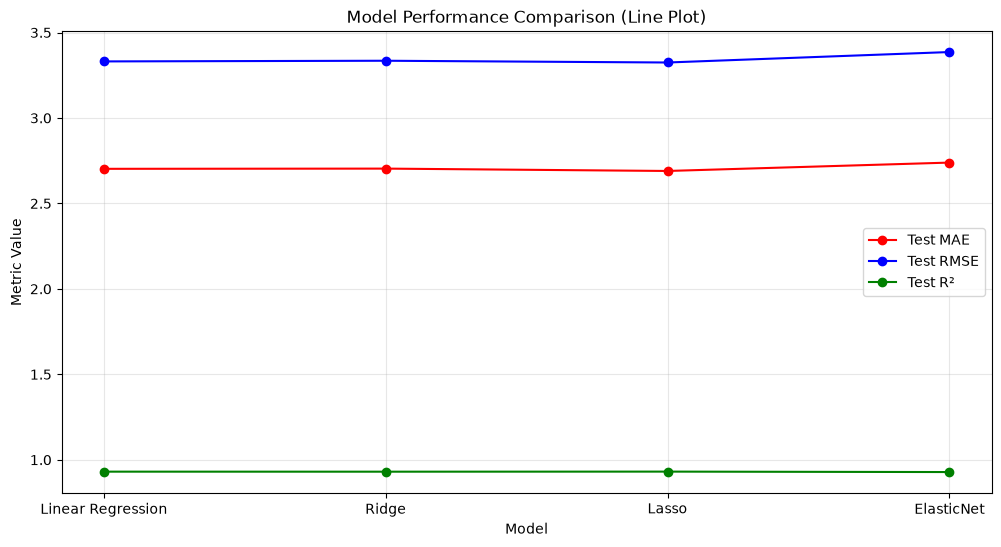

In [73]:
# Prepare data
models = results["Model"].values
mae = results["Test MAE"].values
rmse = results["Test RMSE"].values
r2 = results["Test R²"].values

plt.figure(figsize=(12, 6))

# MAE line
plt.plot(models, mae, marker="o", linestyle="-", color="red", label="Test MAE")

# RMSE line
plt.plot(models, rmse, marker="o", linestyle="-", color="blue", label="Test RMSE")

# R² line
plt.plot(models, r2, marker="o", linestyle="-", color="green", label="Test R²")

plt.title("Model Performance Comparison (Line Plot)")
plt.xlabel("Model")
plt.ylabel("Metric Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [75]:
# --- Retrain all four models with engineered features ---

# Select features (include engineered ones + originals you want)
FEATURES = [
    "RunDiff", "R_perG", "H_perG", "BattingAvg", "SO_perOut", "PitchStrength", "R_adj"
    # add other original features if needed
]

X = data_df[FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale for linear models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train all four models
lr = LinearRegression().fit(X_train_scaled, y_train)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_scaled, y_train)
lasso = LassoCV(alphas=np.logspace(-3, 3, 50), cv=5, max_iter=5000).fit(X_train_scaled, y_train)
elastic = ElasticNetCV(
    l1_ratio=[.1, .5, .7, .9, .95, .99, 1],
    alphas=np.logspace(-3, 2, 50),
    cv=5,
    max_iter=5000,
    random_state=42
).fit(X_train_scaled, y_train)

# Predictions
lr_preds = lr.predict(X_test_scaled)
ridge_preds = ridge.predict(X_test_scaled)
lasso_preds = lasso.predict(X_test_scaled)
elastic_preds = elastic.predict(X_test_scaled)

# Comparison table
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "Lasso", "ElasticNet"],
    "Test MAE": [
        mean_absolute_error(y_test, lr_preds),
        mean_absolute_error(y_test, ridge_preds),
        mean_absolute_error(y_test, lasso_preds),
        mean_absolute_error(y_test, elastic_preds)
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_preds)),
        np.sqrt(mean_squared_error(y_test, ridge_preds)),
        np.sqrt(mean_squared_error(y_test, lasso_preds)),
        np.sqrt(mean_squared_error(y_test, elastic_preds))
    ],
    "Test R²": [
        r2_score(y_test, lr_preds),
        r2_score(y_test, ridge_preds),
        r2_score(y_test, lasso_preds),
        r2_score(y_test, elastic_preds)
    ]
})

print("\nModel Performance Comparison:")
print(results.to_string(index=False))



Model Performance Comparison:
            Model  Test MAE  Test RMSE  Test R²
Linear Regression  3.280776   4.132378 0.893135
            Ridge  3.280820   4.132211 0.893143
            Lasso  3.300989   4.154329 0.891996
       ElasticNet  3.299216   4.153368 0.892046


In [76]:
# --- Imports ---
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Random Forest with original features only ---
ORIGINAL_FEATURES = [
    "R", "RA", "H", "AB", "SO", "ERA", "IPouts"
    # add whichever original columns you used before
]

X = data_df[ORIGINAL_FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest
rf_base = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
rf_base.fit(X_train, y_train)

# Predictions
rf_base_preds = rf_base.predict(X_test)

# Evaluation
print("Random Forest (Original Features) Performance")
print("  Test MAE:", mean_absolute_error(y_test, rf_base_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, rf_base_preds)))
print("  Test R²:", r2_score(y_test, rf_base_preds))

# Top 10 features
rf_base_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_base.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Features (Random Forest, Original Features):")
print(rf_base_importance.head(10))

Random Forest (Original Features) Performance
  Test MAE: 3.4352061248527677
  Test RMSE: 4.396624963747674
  Test R²: 0.8790307172638587

Top 10 Features (Random Forest, Original Features):
  Feature  Importance
0       R    0.466705
1      RA    0.415794
5     ERA    0.039130
6  IPouts    0.029588
2       H    0.016951
3      AB    0.015923
4      SO    0.015910


In [77]:
# --- Retrain Random Forest with engineered features ---

FEATURES = [
    "RunDiff", "R_perG", "H_perG", "BattingAvg", "SO_perOut", "PitchStrength", "R_adj"
    # add other original features if needed
]

X = data_df[FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest
rf = RandomForestRegressor(
    n_estimators=300,   # number of trees
    max_depth=None,     # let trees grow fully
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# Predictions
rf_preds = rf.predict(X_test)

# Evaluation
print("Random Forest Performance")
print("  Test MAE:", mean_absolute_error(y_test, rf_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)))
print("  Test R²:", r2_score(y_test, rf_preds))

# Top 10 features
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Features (Random Forest):")
print(rf_importance.head(10))

Random Forest Performance
  Test MAE: 3.529434628975265
  Test RMSE: 4.385414921774326
  Test R²: 0.8796467998118989

Top 10 Features (Random Forest):
         Feature  Importance
0        RunDiff    0.903741
4      SO_perOut    0.029440
5  PitchStrength    0.016717
6          R_adj    0.014906
1         R_perG    0.013630
2         H_perG    0.011308
3     BattingAvg    0.010259


In [78]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Original features only
ORIGINAL_FEATURES = ["R", "RA", "H", "AB", "SO", "ERA", "IPouts"]

X = data_df[ORIGINAL_FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gb_orig = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)
gb_orig.fit(X_train, y_train)

gb_orig_preds = gb_orig.predict(X_test)

print("Gradient Boosting (Original Features) Performance")
print("  Test MAE:", mean_absolute_error(y_test, gb_orig_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, gb_orig_preds)))
print("  Test R²:", r2_score(y_test, gb_orig_preds))

gb_orig_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_orig.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Features (GB, Original Features):")
print(gb_orig_importance.head(10))


Gradient Boosting (Original Features) Performance
  Test MAE: 3.3286887262647564
  Test RMSE: 4.356913527766772
  Test R²: 0.881206099110378

Top 10 Features (GB, Original Features):
  Feature  Importance
0       R    0.453893
1      RA    0.447978
6  IPouts    0.044148
5     ERA    0.022355
2       H    0.011793
3      AB    0.010623
4      SO    0.009210


In [79]:
# Engineered + original features
NEW_FEATURES = [
    "RunDiff", "R_perG", "H_perG", "BattingAvg", "SO_perOut", "PitchStrength", "R_adj",
    "R", "RA", "H", "AB", "SO", "ERA", "IPouts"
]

X = data_df[NEW_FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gb_new = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)
gb_new.fit(X_train, y_train)

gb_new_preds = gb_new.predict(X_test)

print("Gradient Boosting (Engineered Features) Performance")
print("  Test MAE:", mean_absolute_error(y_test, gb_new_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, gb_new_preds)))
print("  Test R²:", r2_score(y_test, gb_new_preds))

gb_new_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_new.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Features (GB, Engineered Features):")
print(gb_new_importance.head(10))


Gradient Boosting (Engineered Features) Performance
  Test MAE: 3.2503058080762264
  Test RMSE: 4.099622397396858
  Test R²: 0.894822225555805

Top 10 Features (GB, Engineered Features):
       Feature  Importance
0      RunDiff    0.901714
13      IPouts    0.032249
10          AB    0.010182
3   BattingAvg    0.007651
11          SO    0.006081
2       H_perG    0.005892
4    SO_perOut    0.005526
9            H    0.005370
7            R    0.004955
6        R_adj    0.004902


In [80]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Original features only
ORIGINAL_FEATURES = ["R", "RA", "H", "AB", "SO", "ERA", "IPouts"]

X = data_df[ORIGINAL_FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train XGBoost
xgb_orig = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_orig.fit(X_train, y_train)

# Predictions
xgb_orig_preds = xgb_orig.predict(X_test)

print("XGBoost (Original Features) Performance")
print("  Test MAE:", mean_absolute_error(y_test, xgb_orig_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, xgb_orig_preds)))
print("  Test R²:", r2_score(y_test, xgb_orig_preds))

# Top 10 features
xgb_orig_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_orig.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Features (XGBoost, Original Features):")
print(xgb_orig_importance.head(10))

XGBoost (Original Features) Performance
  Test MAE: 3.4012696743011475
  Test RMSE: 4.441508457212288
  Test R²: 0.8765482306480408

Top 10 Features (XGBoost, Original Features):
  Feature  Importance
0       R    0.323998
1      RA    0.292587
5     ERA    0.147194
2       H    0.090410
6  IPouts    0.065615
3      AB    0.056257
4      SO    0.023940


In [81]:
# Engineered + original features
NEW_FEATURES = [
    "RunDiff", "R_perG", "H_perG", "BattingAvg", "SO_perOut", "PitchStrength", "R_adj",
    "R", "RA", "H", "AB", "SO", "ERA", "IPouts"
]

X = data_df[NEW_FEATURES]
y = data_df["W"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train XGBoost
xgb_new = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_new.fit(X_train, y_train)

# Predictions
xgb_new_preds = xgb_new.predict(X_test)

print("XGBoost (Engineered Features) Performance")
print("  Test MAE:", mean_absolute_error(y_test, xgb_new_preds))
print("  Test RMSE:", np.sqrt(mean_squared_error(y_test, xgb_new_preds)))
print("  Test R²:", r2_score(y_test, xgb_new_preds))

# Top 10 features
xgb_new_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_new.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 10 Features (XGBoost, Engineered Features):")
print(xgb_new_importance.head(10))


XGBoost (Engineered Features) Performance
  Test MAE: 3.2283236980438232
  Test RMSE: 4.0853077273682725
  Test R²: 0.8955554366111755

Top 10 Features (XGBoost, Engineered Features):
          Feature  Importance
0         RunDiff    0.594908
6           R_adj    0.098710
7               R    0.080704
8              RA    0.072641
13         IPouts    0.031692
10             AB    0.019351
5   PitchStrength    0.018898
12            ERA    0.013376
1          R_perG    0.012592
3      BattingAvg    0.012411



Model Performance Comparison:
            Model  Test MAE  Test RMSE  Test R²
Linear Regression  3.031392   3.763198 0.911376
            Ridge  3.031782   3.765367 0.911274
            Lasso  3.032779   3.769793 0.911065
       ElasticNet  3.050685   3.790789 0.910072
    Random Forest  3.435206   4.396625 0.879031
Gradient Boosting  3.353298   4.190916 0.890086
          XGBoost  3.354254   4.289791 0.884838


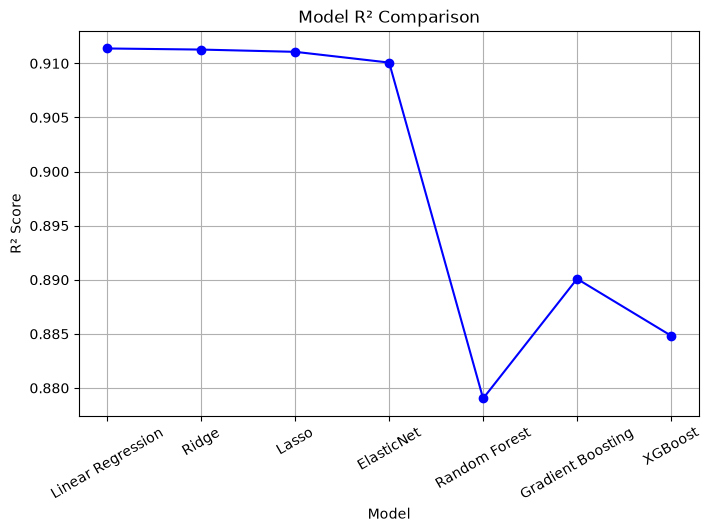

In [19]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb

# --- Define feature sets ---
LINEAR_FEATURES = [
    "R","RA","H","AB","SO","ERA","IPouts",
    "2B","3B","BB","BBA","CG"   # include all columns you used at fit
]
RF_FEATURES = ["R","RA","H","AB","SO","ERA","IPouts"]
GB_XGB_FEATURES = [
    "RunDiff","R_perG","H_perG","BattingAvg","SO_perOut","PitchStrength","R_adj",
    "R","RA","H","AB","SO","ERA","IPouts"
]

y = data_df["W"]

# --- Linear models (scaled full feature set) ---
X_lin = data_df[LINEAR_FEATURES]
X_train_lin, X_test_lin, y_train, y_test = train_test_split(X_lin, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_lin)
X_test_scaled  = scaler.transform(X_test_lin)

# Instantiate linear models
lr = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=0.01)
elastic = ElasticNet(alpha=0.01, l1_ratio=0.5)

# Fit linear models
lr.fit(X_train_scaled, y_train)
ridge.fit(X_train_scaled, y_train)
lasso.fit(X_train_scaled, y_train)
elastic.fit(X_train_scaled, y_train)

# --- Random Forest (original features) ---
X_rf = data_df[RF_FEATURES]
X_train_rf, X_test_rf, _, _ = train_test_split(X_rf, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X_train_rf, y_train)

# --- Gradient Boosting / XGBoost (engineered features) ---
X_new = data_df[GB_XGB_FEATURES]
X_train_new, X_test_new, _, _ = train_test_split(X_new, y, test_size=0.2, random_state=42)

gb_new = GradientBoostingRegressor(n_estimators=300, random_state=42)
gb_new.fit(X_train_new, y_train)

xgb_new = xgb.XGBRegressor(n_estimators=300, random_state=42)
xgb_new.fit(X_train_new, y_train)

# --- Collect results ---
results = []

# Linear models
for name, model, X_test in [
    ("Linear Regression", lr, X_test_scaled),
    ("Ridge", ridge, X_test_scaled),
    ("Lasso", lasso, X_test_scaled),
    ("ElasticNet", elastic, X_test_scaled)
]:
    preds = model.predict(X_test)
    results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, preds),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "Test R²": r2_score(y_test, preds)
    })

# Random Forest
rf_preds = rf.predict(X_test_rf)
results.append({
    "Model": "Random Forest",
    "Test MAE": mean_absolute_error(y_test, rf_preds),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, rf_preds)),
    "Test R²": r2_score(y_test, rf_preds)
})

# Gradient Boosting
gb_preds = gb_new.predict(X_test_new)
results.append({
    "Model": "Gradient Boosting",
    "Test MAE": mean_absolute_error(y_test, gb_preds),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, gb_preds)),
    "Test R²": r2_score(y_test, gb_preds)
})

# XGBoost
xgb_preds = xgb_new.predict(X_test_new)
results.append({
    "Model": "XGBoost",
    "Test MAE": mean_absolute_error(y_test, xgb_preds),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, xgb_preds)),
    "Test R²": r2_score(y_test, xgb_preds)
})

# --- Final table ---
results_df = pd.DataFrame(results)
print("\nModel Performance Comparison:")
print(results_df.to_string(index=False))

import matplotlib.pyplot as plt

# --- Plot R² scores as a line chart ---
plt.figure(figsize=(8,5))
plt.plot(results_df["Model"], results_df["Test R²"], marker="o", linestyle="-", color="b")

plt.title("Model R² Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30)
plt.grid(True)

plt.show()



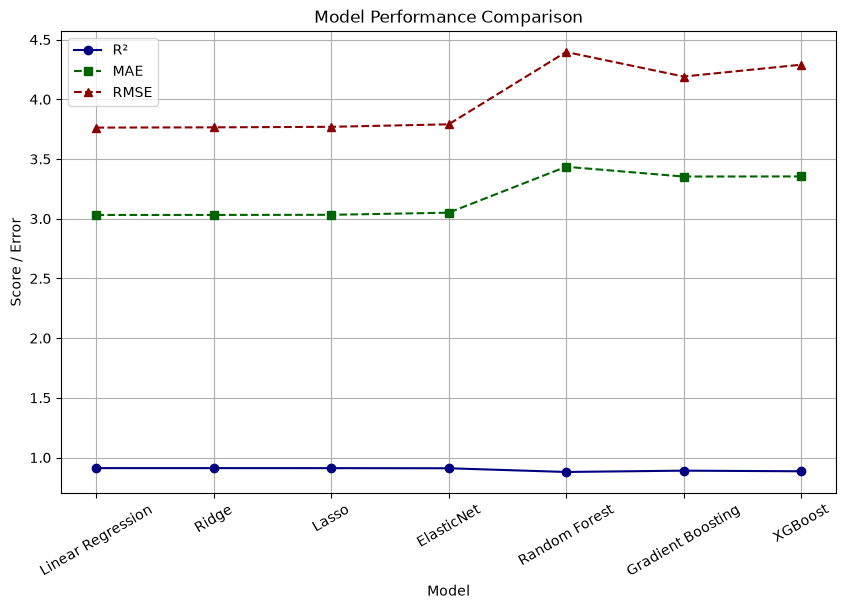

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

# Plot R²
plt.plot(results_df["Model"], results_df["Test R²"], marker="o", linestyle="-", color="navy", label="R²")

# Plot MAE
plt.plot(results_df["Model"], results_df["Test MAE"], marker="s", linestyle="--", color="darkgreen", label="MAE")

# Plot RMSE
plt.plot(results_df["Model"], results_df["Test RMSE"], marker="^", linestyle="--", color="darkred", label="RMSE")

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score / Error")
plt.xticks(rotation=30)
plt.legend()
plt.grid(True)

plt.show()
